In [6]:
import os

print(os.getcwd())
print(os.listdir())

/Users/sanikadhide/Desktop/ML ASSIGNMENTS
['ML 4.ipynb', '.DS_Store', 'ML 2.ipynb', 'ML 5.ipynb', 'uber.csv', 'ML 3.ipynb', 'wine (1).csv', 'ML 1.ipynb', 'Iris.csv', 'car_evaluation copy.csv', '.ipynb_checkpoints']


First 5 rows:
       0      1  2  3      4     5      6
0  vhigh  vhigh  2  2  small   low  unacc
1  vhigh  vhigh  2  2  small   med  unacc
2  vhigh  vhigh  2  2  small  high  unacc
3  vhigh  vhigh  2  2    med   low  unacc
4  vhigh  vhigh  2  2    med   med  unacc

Dataset Shape:
(1728, 7)

Column Names:
['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

Missing Values:
buying      0
maint       0
doors       0
persons     0
lug_boot    0
safety      0
class       0
dtype: int64

Features:
  buying  maint doors persons lug_boot safety
0  vhigh  vhigh     2       2    small    low
1  vhigh  vhigh     2       2    small    med
2  vhigh  vhigh     2       2    small   high
3  vhigh  vhigh     2       2      med    low
4  vhigh  vhigh     2       2      med    med

Target:
0    unacc
1    unacc
2    unacc
3    unacc
4    unacc
Name: class, dtype: object

Encoded Features:
   buying  maint  doors  persons  lug_boot  safety
0       3      3      0        0         2    

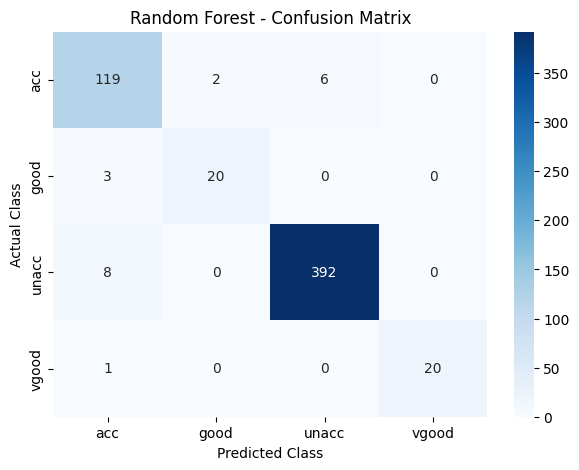


Feature Importance:
safety      0.277876
persons     0.222559
buying      0.177152
maint       0.155991
lug_boot    0.094410
doors       0.072011
dtype: float64


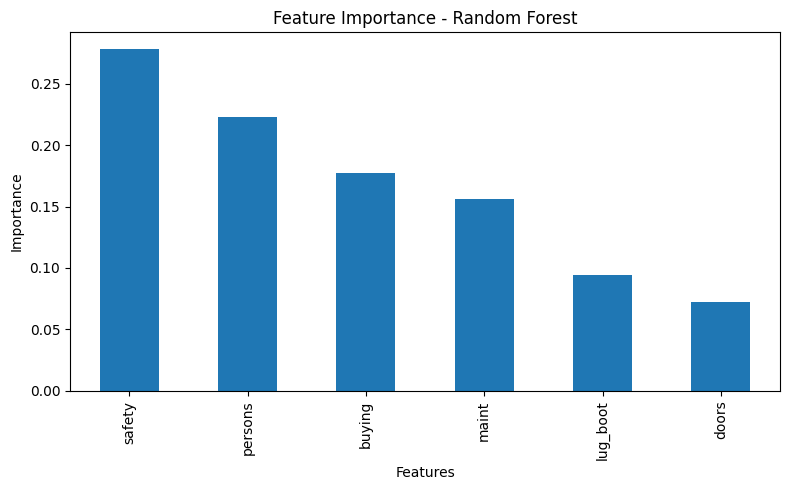

In [4]:
# Random Forest Classifier for Car Evaluation

# Step 1: Import Libraries
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Step 2: Load Dataset
df = pd.read_csv("car_evaluation.csv", header=None)

print("First 5 rows:")
print(df.head())

print("\nDataset Shape:")
print(df.shape)

# Step 3: Add Column Names
df.columns = [
    "buying",
    "maint",
    "doors",
    "persons",
    "lug_boot",
    "safety",
    "class"
]

print("\nColumn Names:")
print(df.columns.tolist())

# Step 4: Check Missing Values
print("\nMissing Values:")
print(df.isnull().sum())

# Step 5: Separate Features and Target
X = df.drop("class", axis=1)
y = df["class"]

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())

# Step 6: Encode Categorical Data
encoder = LabelEncoder()

for column in X.columns:
    X[column] = encoder.fit_transform(X[column])

# Encode Target Variable
y_encoder = LabelEncoder()
y = y_encoder.fit_transform(y)

print("\nEncoded Features:")
print(X.head())

# Step 7: Split Dataset
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.33,
    random_state=42,
    stratify=y
)

print("\nTraining Data Shape:")
print(X_train.shape)

print("\nTesting Data Shape:")
print(X_test.shape)

# Step 8: Create Random Forest Classifier
model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

# Step 9: Train the Model
model.fit(X_train, y_train)

print("\nRandom Forest Model Trained Successfully!")

# Step 10: Make Predictions
y_pred = model.predict(X_test)

print("\nPredictions:")
print(y_pred[:5])

# Step 11: Calculate Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("\nAccuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

# Step 12: Classification Report
print("\nClassification Report:")

print(
    classification_report(
        y_test,
        y_pred,
        target_names=y_encoder.classes_
    )
)

# Step 13: Confusion Matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=y_encoder.classes_,
    yticklabels=y_encoder.classes_
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Random Forest - Confusion Matrix")
plt.show()

# Step 14: Feature Importance
feature_importance = pd.Series(
    model.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print("\nFeature Importance:")
print(feature_importance)

plt.figure(figsize=(8, 5))

feature_importance.plot(kind="bar")

plt.title("Feature Importance - Random Forest")
plt.xlabel("Features")
plt.ylabel("Importance")

plt.tight_layout()
plt.show()